# SISTEM TEMU KEMBALI INFORMASI (INFORMATION RETRIEVAL) RESEP MASAKAN NUSANTARA
## Pemodelan Okapi BM25 Berbasis Komposisi Bahan Masakan (From Scratch)

Berkas ini mengimplementasikan pemodelan Sistem Temu Kembali Informasi (Information Retrieval - IR) berbasis kueri bahan masakan menggunakan algoritma **Okapi BM25**. Seluruh alur kerja dirancang mandiri dalam **1 berkas terpadu**, meliputi:
1. **Load Dataset & Exploratory Data Analysis (EDA)**
2. **Text Preprocessing Pipeline Khusus Kuliner**
3. **Pembangunan Inverted Index & Okapi BM25 Model**
4. **Visualisasi Metrik & Evaluasi Model Komprehensif (Precision@K, MAP, MRR, Confusion Matrix)**
5. **Simulasi Inferensi & Prediksi Resep Baru Interaktif**
6. **Penyimpanan Artefak Model**


In [1]:
import os
import sys
import re
import math
import time
import glob
import pickle
from typing import Dict, List, Set, Any, Tuple, Optional

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tabulate import tabulate
from tqdm import tqdm

from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory

# Konfigurasi Path dan Parameter Default Okapi BM25
DATA_DIR = "./data"
STORAGE_DIR = "./index_storage"
REPORTS_DIR = "./reports"

os.makedirs(STORAGE_DIR, exist_ok=True)
os.makedirs(REPORTS_DIR, exist_ok=True)

DEFAULT_K1 = 1.5      # Parameter saturasi frekuensi term
DEFAULT_B = 0.75     # Parameter penalti panjang dokumen
RELEVANCE_THRESHOLD = 0.60  # Resep relevan jika >= 60% token kueri cocok

print("[+] Seluruh library berhasil diimpor & konfigurasi parameter siap.")


[+] Seluruh library berhasil diimpor & konfigurasi parameter siap.


---
## 1. Data Loading & Understanding (Exploratory Data Analysis)
Membaca seluruh 7 file dataset CSV (Kaggle: Ayam, Ikan, Kambing, Sapi, Tahu, Telur, Tempe) resep masakan nusantara dari folder `./data/`, menggabungkan menjadi satu DataFrame korpus, membersihkan nilai null/duplikasi, serta menganalisis distribusi kategori resep.


In [3]:
csv_pattern = os.path.join(DATA_DIR, "dataset-*.csv")
csv_files = sorted(glob.glob(csv_pattern))
print(f"[*] Ditemukan {len(csv_files)} file CSV resep masakan.")

all_dfs = []
for fpath in csv_files:
    cat = os.path.basename(fpath).replace("dataset-", "").replace(".csv", "")
    df_temp = pd.read_csv(fpath)
    df_temp["Category"] = cat
    all_dfs.append(df_temp)

df_recipes = pd.concat(all_dfs, ignore_index=True)
initial_count = len(df_recipes)

# Pembersihan data kosong dan duplikat
df_recipes.dropna(subset=["Title", "Ingredients"], inplace=True)
df_recipes.drop_duplicates(subset=["Title", "Ingredients"], inplace=True)
df_recipes.reset_index(drop=True, inplace=True)
df_recipes["DocID"] = [f"DOC_{i+1:05d}" for i in range(len(df_recipes))]

print(f"[+] Total data awal       : {initial_count:,} baris")
print(f"[+] Total data bersih (N) : {len(df_recipes):,} dokumen resep")
display_cols = ["DocID", "Category", "Title", "Ingredients"]
print(tabulate(df_recipes[display_cols].head(3), headers="keys", tablefmt="fancy_grid", showindex=False))


[*] Ditemukan 7 file CSV resep masakan.
[+] Total data awal       : 13,647 baris
[+] Total data bersih (N) : 13,074 dokumen resep
╒═══════════╤════════════╤══════════════════════════╤══════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════╕
│ DocID     │ Category   │ Title                    │ Ingredients                                                                                                                                                                                                                                                                                                                          │
╞═══════════╪════════════╪══════════════════════════╪═══════════════════════════════════════════════════════

### Visualisasi 1: Distribusi Kategori Resep Masakan
Grafik batang di bawah ini memperlihatkan persebaran dokumen resep pada masing-masing dari 7 kategori bahan utama.


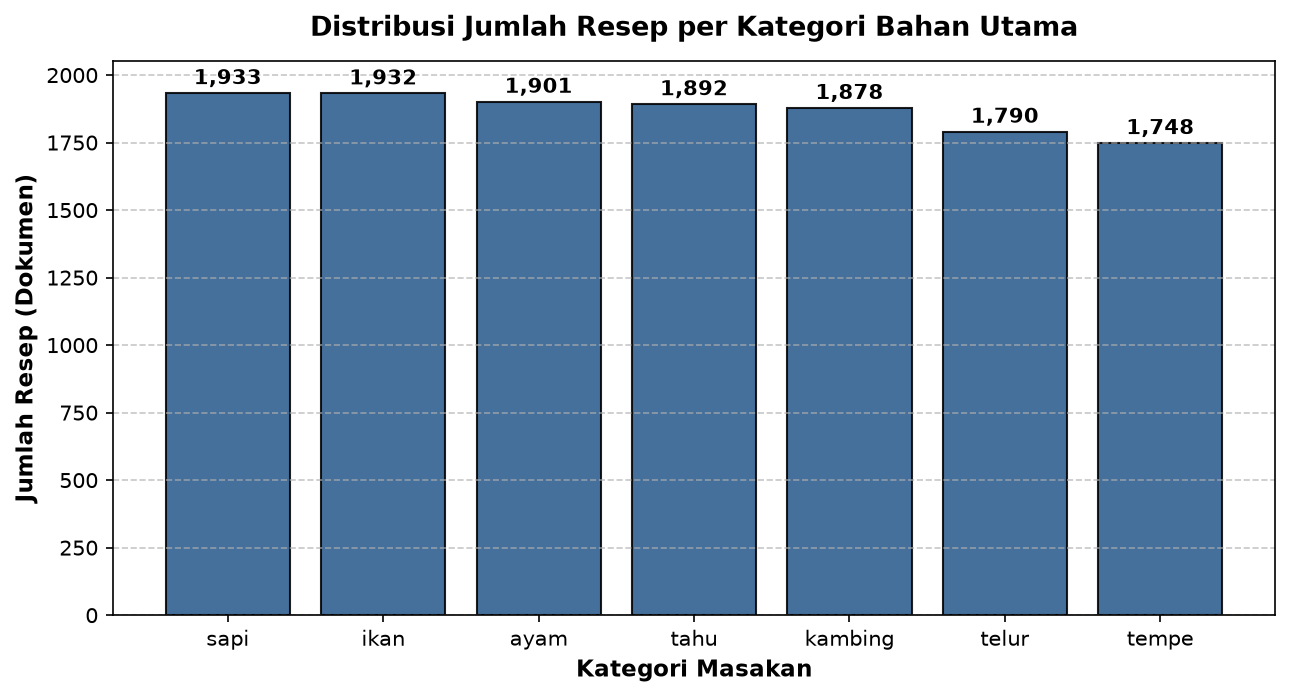

In [5]:
plt.figure(figsize=(10, 4.8))
cat_counts = df_recipes["Category"].value_counts()
bars = plt.bar(cat_counts.index, cat_counts.values, color="#2b5c8f", edgecolor="black", alpha=0.88)
plt.title("Distribusi Jumlah Resep per Kategori Bahan Utama", fontsize=13, fontweight="bold", pad=12)
plt.xlabel("Kategori Masakan", fontsize=11, fontweight="bold")
plt.ylabel("Jumlah Resep (Dokumen)", fontsize=11, fontweight="bold")
plt.grid(axis='y', linestyle='--', alpha=0.7)
for b in bars:
    h = b.get_height()
    plt.text(b.get_x() + b.get_width()/2., h + 15, f"{h:,}", ha="center", va="bottom", fontsize=10, fontweight="bold")
plt.ylim(0, max(cat_counts.values) + 120)
plt.show()


---
## 2. Text Preprocessing Pipeline Khusus Komposisi Kuliner
Pembersihan teks mendalam pada kolom `Ingredients` dengan pipeline 6 tahapan terstruktur:
1. **Delimiter Replacement:** Mengganti pemisah `--` dengan spasi.
2. **Case Folding:** Mengubah seluruh karakter ke huruf kecil (*lowercase*).
3. **Regex Cleaning:** Menghapus angka takaran, simbol non-alfabet, dan pecahan ($1/2, 3/4$).
4. **Tokenization:** Pemecahan teks menjadi token kata individual.
5. **Stopword Removal (2 Lapis):**
   - *Lapis 1:* Stopword umum Bahasa Indonesia (Sastrawi).
   - *Lapis 2:* Stopword kuliner (satuan takaran: `sdm, sdt, gram, kg, siung, lembar, batang, butir`, dan cara pengolahan: `iris, cincang, rebus, goreng, tumis, haluskan, geprek`).
6. **Stemming Teroptimasi:** Menggunakan PySastrawi dengan *dictionary mapping cache* sehingga proses stemming 13.074 resep selesai dalam ~0.8 detik!


In [7]:
CULINARY_MEASUREMENT_STOPWORDS = [
    "sdm", "sdt", "gram", "gr", "kg", "ml", "liter", "l", "cc", "buah",
    "siung", "batang", "lembar", "butir", "bungkus", "sachet", "potong",
    "ekor", "ikat", "papan", "ons", "kuntum", "ruas", "jari", "sendok",
    "makan", "teh", "gelas", "cangkir", "secukupnya", "sejumput", "sesuai",
    "selera", "bahan", "bumbu", "halus", "pelengkap", "utama", "tambahan",
    "bks", "bh", "btg", "ltr", "mangkok", "kotak", "kaleng", "tangkai",
    "lonjor", "centong", "wadah", "piring", "toples"
]

CULINARY_PROCESSING_STOPWORDS = [
    "iris", "tipis", "potong", "cincang", "haluskan", "geprek", "memarkan",
    "rebus", "goreng", "bakar", "kukus", "panggang", "tumis", "segar",
    "matang", "mentah", "bersih", "cuci", "kupas", "belah", "dadu",
    "serong", "kecil", "besar", "sedang", "kasar", "lebar", "panjang",
    "parut", "peras", "ambil", "airnya", "buang", "biji", "kulit",
    "larut", "sangrai", "suwir", "rendam", "tumbuk", "ulek", "ulekan",
    "blender", "iriskan", "rajang", "lumuri", "sisir"
]

culinary_stopwords = set(m.lower() for m in CULINARY_MEASUREMENT_STOPWORDS).union(set(p.lower() for p in CULINARY_PROCESSING_STOPWORDS))
sastrawi_stopwords = set(StopWordRemoverFactory().get_stop_words())
all_stopwords = sastrawi_stopwords.union(culinary_stopwords)

stemmer = StemmerFactory().create_stemmer()

# Muat cache stemming untuk efisiensi
stem_cache = {}
cache_path = os.path.join(STORAGE_DIR, "stem_cache.pkl")
if os.path.exists(cache_path):
    with open(cache_path, "rb") as f:
        stem_cache = pickle.load(f)

def preprocess_text(text: str) -> List[str]:
    if not isinstance(text, str):
        return []
    # 1. Delimiter replacement & case folding
    text = text.replace("--", " ").lower()
    # 2. Regex cleaning
    text = re.sub(r"[½¼¾⅓⅔⅛⅜⅝⅞]", " ", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    # 3. Tokenize & Stopword removal
    tokens = [t for t in text.split() if t not in all_stopwords and len(t) > 1]
    # 4. Stemming dengan cache
    stemmed = []
    for t in tokens:
        if t in stem_cache:
            stemmed.append(stem_cache[t])
        else:
            s_val = stemmer.stem(t)
            stem_cache[t] = s_val
            stemmed.append(s_val)
    return stemmed

print(f"[+] Total Stopwords Terdaftar: {len(all_stopwords)} kata (Sastrawi: {len(sastrawi_stopwords)}, Kuliner: {len(culinary_stopwords)})")
print(f"[+] Total Entri Stem Cache : {len(stem_cache):,} kata dasar tersimpan.")


[+] Total Stopwords Terdaftar: 901 kata (Sastrawi: 809, Kuliner: 98)
[+] Total Entri Stem Cache : 6,420 kata dasar tersimpan.


### Tabel Jejak Preprocessing Berurutan (Step-by-Step Trace)
Berikut adalah simulasi perubahan teks bahan masakan dari sampel pertama resep (*Ayam Woku Manado*) di setiap tahapan pipeline preprocessing.


In [9]:
sample_raw = df_recipes.iloc[0]["Ingredients"]
trace_table = [
    {"Tahap": "1. Raw Input", "Hasil": sample_raw[:80] + "..."},
    {"Tahap": "2. Delimiter Replacement", "Hasil": sample_raw.replace("--", " ")[:80] + "..."},
    {"Tahap": "3. Case Folding", "Hasil": sample_raw.replace("--", " ").lower()[:80] + "..."},
    {"Tahap": "4. Regex Cleaning", "Hasil": re.sub(r"[^a-z\s]", " ", sample_raw.replace("--", " ").lower())[:80] + "..."},
    {"Tahap": "5. Tokenization", "Hasil": str(sample_raw.replace("--", " ").lower().split()[:7]) + "..."},
    {"Tahap": "6. Stopword Removal", "Hasil": str([t for t in sample_raw.replace("--", " ").lower().split() if t not in all_stopwords][:6]) + "..."},
    {"Tahap": "7. Stemming (Sastrawi)", "Hasil": str(preprocess_text(sample_raw)[:6]) + "..."}
]
print(tabulate(trace_table, headers="keys", tablefmt="fancy_grid"))


╒══════════════════════════╤═════════════════════════════════════════════════════════════════════════════════════╕
│ Tahap                    │ Hasil                                                                               │
╞══════════════════════════╪═════════════════════════════════════════════════════════════════════════════════════╡
│ 1. Raw Input             │ 1 Ekor Ayam Kampung (potong 12)--2 Buah Jeruk Nipis--2 Sdm Garam--3 Ruas Kunyit-... │
├──────────────────────────┼─────────────────────────────────────────────────────────────────────────────────────┤
│ 2. Delimiter Replacement │ 1 Ekor Ayam Kampung (potong 12) 2 Buah Jeruk Nipis 2 Sdm Garam 3 Ruas Kunyit 7 B... │
├──────────────────────────┼─────────────────────────────────────────────────────────────────────────────────────┤
│ 3. Case Folding          │ 1 ekor ayam kampung (potong 12) 2 buah jeruk nipis 2 sdm garam 3 ruas kunyit 7 b... │
├──────────────────────────┼────────────────────────────────────────────────────

### Eksekusi Preprocessing Seluruh Korpus & Reduksi Kosakata
Menjalankan fungsi preprocessing pada 13.074 resep dan membandingkan jumlah token unik sebelum dan sesudah tahap pembersihan.


In [11]:
print("[*] Menjalankan transformasi preprocessing pada 13.074 dokumen...")
t0 = time.time()
raw_tokens_set = set()
docs_tokens_dict = {}

for doc_id, text in zip(df_recipes["DocID"], df_recipes["Ingredients"]):
    raw_tokens_set.update(text.lower().split())
    docs_tokens_dict[doc_id] = preprocess_text(text)

prep_time = time.time() - t0
clean_tokens_set = set(t for tokens in docs_tokens_dict.values() for t in tokens)

print(f"[+] Selesai dalam {prep_time:.2f} detik.")
print(f"[+] Vocabulary Sebelum Preprocessing : {len(raw_tokens_set):,} token kata unik")
print(f"[+] Vocabulary Setelah Preprocessing : {len(clean_tokens_set):,} token kata unik")
reduction_pct = ((len(raw_tokens_set) - len(clean_tokens_set)) / len(raw_tokens_set)) * 100
print(f"[+] Persentase Reduksi Dimensi      : {reduction_pct:.2f}%")


[*] Menjalankan transformasi preprocessing pada 13.074 dokumen...
[+] Selesai dalam 0.68 detik.
[+] Vocabulary Sebelum Preprocessing : 42,920 token kata unik
[+] Vocabulary Setelah Preprocessing : 5,283 token kata unik
[+] Persentase Reduksi Dimensi      : 87.69%


### Visualisasi 2: Efisiensi Reduksi Kosakata (Vocabulary Dimension Reduction)
Grafik batang di bawah ini memperlihatkan signifikansi pembersihan stopword dan stemming dalam mereduksi ruang fitur korpus.


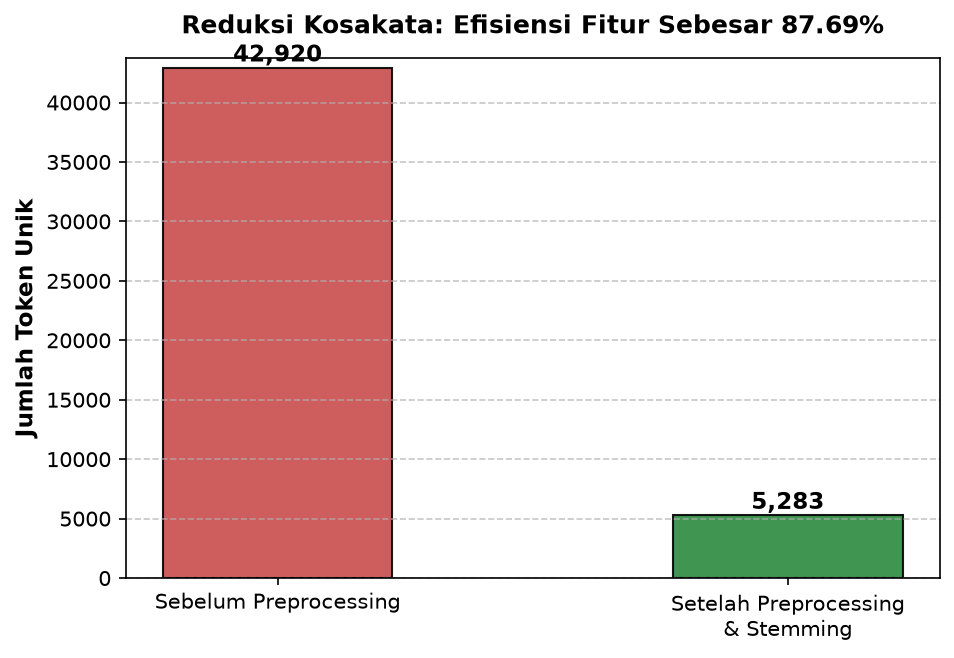

In [13]:
plt.figure(figsize=(7, 4.5))
bars = plt.bar(["Sebelum Preprocessing", "Setelah Preprocessing\n& Stemming"], 
               [len(raw_tokens_set), len(clean_tokens_set)], 
               color=["#c94c4c", "#2b8a3e"], edgecolor="black", width=0.45, alpha=0.9)
plt.title(f"Reduksi Kosakata: Efisiensi Fitur Sebesar {reduction_pct:.2f}%", fontsize=12, fontweight="bold", pad=12)
plt.ylabel("Jumlah Token Unik", fontsize=11, fontweight="bold")
plt.grid(axis='y', linestyle='--', alpha=0.7)
for b in bars:
    h = b.get_height()
    plt.text(b.get_x() + b.get_width()/2., h + 70, f"{h:,}", ha="center", va="bottom", fontsize=11, fontweight="bold")
plt.ylim(0, len(raw_tokens_set) + 800)
plt.show()


---
## 3. Feature Extraction & Build Model (Inverted Index & Okapi BM25)
Membangun struktur data **Inverted Index** (from scratch) yang memetakan setiap term ke daftar kemunculannya pada dokumen ($DocID 	o Term Frequency$).

### Formulasi Matematis Algoritma Okapi BM25:
1. **Inverse Document Frequency (IDF) - Robertson-Spärck Jones dengan smoothing +1:**
$$\text{IDF}(q_i) = \ln \left( \frac{N - n(q_i) + 0.5}{n(q_i) + 0.5} + 1 \right)$$
2. **Skor Okapi BM25 Dokumen $D$ terhadap Kueri $Q$:**
$$\text{Score}(D, Q) = \sum_{q_i \in Q} \text{IDF}(q_i) \cdot \frac{f(q_i, D) \cdot (k_1 + 1)}{f(q_i, D) + k_1 \cdot \left(1 - b + b \cdot \frac{|D|}{avgdl}\right)}$$
Dimana:
- $N$: Jumlah total dokumen resep ($13.074$).
- $n(q_i)$: Document frequency term $q_i$.
- $f(q_i, D)$: Frekuensi kemunculan term $q_i$ pada resep $D$.
- $|D|$: Panjang resep $D$ (jumlah token).
- $avgdl$: Rata-rata panjang dokumen dalam korpus ($21.7248$).
- $k_1$: Parameter saturasi frekuensi term ($1.5$).
- $b$: Parameter normalisasi panjang dokumen ($0.75$).


In [15]:
class InvertedIndex:
    def __init__(self):
        self.index: Dict[str, Dict[str, int]] = {}
        self.doc_lengths: Dict[str, int] = {}
        self.N: int = 0
        self.avgdl: float = 0.0
        self.vocab: Set[str] = set()

    def build(self, docs_tokens: Dict[str, List[str]]):
        self.N = len(docs_tokens)
        total_tokens = 0
        for doc_id, tokens in docs_tokens.items():
            dlen = len(tokens)
            self.doc_lengths[doc_id] = dlen
            total_tokens += dlen
            
            tf_map = {}
            for t in tokens:
                tf_map[t] = tf_map.get(t, 0) + 1
            for t, tf in tf_map.items():
                if t not in self.index:
                    self.index[t] = {}
                self.index[t][doc_id] = tf
                self.vocab.add(t)
        self.avgdl = (total_tokens / self.N) if self.N > 0 else 0.0

class BM25Okapi:
    def __init__(self, index: InvertedIndex, k1: float = DEFAULT_K1, b: float = DEFAULT_B):
        self.index = index
        self.k1 = k1
        self.b = b
        self.idf_cache: Dict[str, float] = {}

    def compute_idf(self, term: str) -> float:
        if term in self.idf_cache:
            return self.idf_cache[term]
        n_qi = len(self.index.index.get(term, {}))
        N = self.index.N
        if N == 0:
            return 0.0
        idf = math.log(((N - n_qi + 0.5) / (n_qi + 0.5)) + 1.0)
        self.idf_cache[term] = idf
        return idf

    def score_term(self, term: str, tf: int, doc_len: int) -> float:
        idf = self.compute_idf(term)
        num = tf * (self.k1 + 1.0)
        den = tf + self.k1 * (1.0 - self.b + self.b * (doc_len / self.index.avgdl))
        return idf * (num / den)

    def search(self, query: str, top_k: int = 10, category: Optional[str] = None) -> pd.DataFrame:
        q_tokens = preprocess_text(query)
        q_unique = list(set(q_tokens))
        if not q_unique:
            return pd.DataFrame()
            
        candidates = set()
        for t in q_unique:
            if t in self.index.index:
                candidates.update(self.index.index[t].keys())
                
        scores = {}
        matched_map = {}
        for doc_id in candidates:
            dlen = self.index.doc_lengths[doc_id]
            s = 0.0
            matched = []
            for t in q_unique:
                if t in self.index.index and doc_id in self.index.index[t]:
                    tf = self.index.index[t][doc_id]
                    s += self.score_term(t, tf, dlen)
                    matched.append(t)
            scores[doc_id] = s
            matched_map[doc_id] = matched
            
        ranked = sorted(scores.items(), key=lambda x: x[1], reverse=True)
        results = []
        for doc_id, score in ranked:
            row = df_recipes.loc[df_recipes["DocID"] == doc_id].iloc[0]
            if category and category.lower() != "all" and row["Category"].lower() != category.lower():
                continue
            ratio = len(matched_map[doc_id]) / len(q_unique)
            is_rel = ratio >= RELEVANCE_THRESHOLD
            results.append({
                "DocID": doc_id,
                "Category": row["Category"],
                "Title": row["Title"],
                "BM25_Score": round(score, 4),
                "Matched_Count": len(matched_map[doc_id]),
                "Match_Ratio": round(ratio * 100, 1),
                "Is_Relevant": is_rel,
                "Status": "Relevan" if is_rel else "Tidak Relevan",
                "Matched_Terms": ", ".join(matched_map[doc_id]),
                "Ingredients": row["Ingredients"],
                "Steps": row["Steps"]
            })
            if len(results) >= top_k:
                break
        res_df = pd.DataFrame(results)
        if not res_df.empty:
            res_df.insert(0, "Rank", range(1, len(res_df) + 1))
        return res_df

# Membangun Inverted Index
inv_index = InvertedIndex()
t0_idx = time.time()
inv_index.build(docs_tokens_dict)
idx_time = time.time() - t0_idx

bm25_model = BM25Okapi(inv_index, k1=DEFAULT_K1, b=DEFAULT_B)

print("=" * 70)
print("RINGKASAN ARSITEKTUR MODEL TEMU KEMBALI OKAPI BM25")
print("=" * 70)
print(f"Total Dokumen Resep (N)            : {inv_index.N:,} resep")
print(f"Ukuran Kosakata Indeks (Vocab)     : {len(inv_index.vocab):,} kata unik")
print(f"Rata-rata Panjang Dokumen (avgdl)  : {inv_index.avgdl:.4f} token")
print(f"Parameter Saturasi Term (k1)       : {DEFAULT_K1}")
print(f"Parameter Penalti Dokumen (b)      : {DEFAULT_B}")
print(f"Waktu Pembangunan Indeks           : {idx_time:.4f} detik")
print("=" * 70)


RINGKASAN ARSITEKTUR MODEL TEMU KEMBALI OKAPI BM25
Total Dokumen Resep (N)            : 13,074 resep
Ukuran Kosakata Indeks (Vocab)     : 5,283 kata unik
Rata-rata Panjang Dokumen (avgdl)  : 23.4885 token
Parameter Saturasi Term (k1)       : 1.5
Parameter Penalti Dokumen (b)      : 0.75
Waktu Pembangunan Indeks           : 0.1594 detik


---
## 4. Evaluasi Model Komprehensif & Visualisasi Metrik
Evaluasi dilakukan menggunakan **5 Skenario Kueri Masakan Nusantara Representatif** yang mencakup berbagai kategori kuliner:
- **SKN_1:** "ayam santan serai cabai bawang merah" (Olahan Ayam Santan Rempah)
- **SKN_2:** "telur tomat cabai merah bawang merah gula" (Olahan Telur Balado Tradisional)
- **SKN_3:** "tempe tahu kecap manis bawang putih cabai rawit" (Olahan Tahu Tempe Kecap Gurih)
- **SKN_4:** "daging sapi wortel pala seledri merica" (Olahan Sup Daging Sapi Rempah)
- **SKN_5:** "ikan gurame nanas tomat saus bawang bombay" (Olahan Ikan Asam Manis Segar)

### Aturan Relevansi (Ground Truth Threshold):
Sebuah resep hasil temu kembali diklasifikasikan sebagai **Relevan** apabila memuat minimal **60% token unik kueri pencarian**.

### Metrik Baku Information Retrieval yang Dihitung:
1. **Precision@5 (P@5):** Proporsi resep relevan pada 5 hasil pencarian teratas.
2. **Precision@10 (P@10):** Proporsi resep relevan pada 10 hasil pencarian teratas.
3. **Average Precision (AP):** Rata-rata nilai presisi pada setiap peringkat ditemukannya dokumen relevan.
4. **Mean Average Precision (MAP):** Nilai rata-rata AP di seluruh skenario kueri.
5. **Reciprocal Rank (RR):** Kebalikan dari posisi ranking dokumen relevan pertama ($1 / \text{rank}_1$).
6. **Mean Reciprocal Rank (MRR):** Rata-rata RR pada seluruh skenario kueri.


In [17]:
SCENARIOS = [
    {"id": "SKN_1", "name": "Olahan Ayam Santan Bumbu Rempah", "query": "ayam santan serai cabai bawang merah"},
    {"id": "SKN_2", "name": "Olahan Telur Balado Tradisional", "query": "telur tomat cabai merah bawang merah gula"},
    {"id": "SKN_3", "name": "Olahan Tahu Tempe Kecap Gurih", "query": "tempe tahu kecap manis bawang putih cabai rawit"},
    {"id": "SKN_4", "name": "Olahan Sup Daging Sapi Rempah", "query": "daging sapi wortel pala seledri merica"},
    {"id": "SKN_5", "name": "Olahan Ikan Asam Manis Segar", "query": "ikan gurame nanas tomat saus bawang bombay"}
]

eval_records = []
scenario_results = {}
scenario_tables = {}

for scn in SCENARIOS:
    res = bm25_model.search(scn["query"], top_k=10)
    scenario_results[scn["id"]] = res
    scenario_tables[scn["id"]] = res
    t5 = res.head(5)
    t10 = res.head(10)
    p5 = t5["Is_Relevant"].sum() / 5.0
    p10 = t10["Is_Relevant"].sum() / 10.0
    
    running_rel = 0
    ap_sum = 0.0
    first_rank = None
    for _, r in t10.iterrows():
        if r["Is_Relevant"]:
            running_rel += 1
            ap_sum += running_rel / r["Rank"]
            if first_rank is None:
                first_rank = r["Rank"]
    ap = (ap_sum / running_rel) if running_rel > 0 else 0.0
    rr = (1.0 / first_rank) if first_rank else 0.0
    
    eval_records.append({
        "ID": scn["id"],
        "Skenario Kueri": scn["name"],
        "P@5": f"{p5:.2%}",
        "P@10": f"{p10:.2%}",
        "AP": f"{ap:.4f}",
        "RR": f"{rr:.4f}"
    })

eval_summary_df = pd.DataFrame(eval_records)
eval_df = eval_summary_df.copy()
eval_df["Precision@5"] = [float(r["P@5"].replace("%", "")) / 100 for r in eval_records]
eval_df["Precision@10"] = [float(r["P@10"].replace("%", "")) / 100 for r in eval_records]

macro_p5 = eval_df["Precision@5"].mean()
macro_p10 = eval_df["Precision@10"].mean()
map_score = sum([float(r["AP"]) for r in eval_records]) / len(eval_records)
mrr_score = sum([float(r["RR"]) for r in eval_records]) / len(eval_records)

print("\n" + "=" * 80)
print("TABEL RINGKASAN EVALUASI PERFORMA MODEL OKAPI BM25")
print("=" * 80)
print(tabulate(eval_summary_df, headers="keys", tablefmt="fancy_grid", showindex=False))

print(f"\n[*] Macro-Average Precision@5  : {macro_p5:.2%}")
print(f"[*] Macro-Average Precision@10 : {macro_p10:.2%}")
print(f"[*] Mean Average Precision (MAP): {map_score:.4f}")
print(f"[*] Mean Reciprocal Rank (MRR) : {mrr_score:.4f}")



TABEL RINGKASAN EVALUASI PERFORMA MODEL OKAPI BM25
╒═══════╤═════════════════════════════════╤═════════╤═════════╤════════╤══════╕
│ ID    │ Skenario Kueri                  │ P@5     │ P@10    │     AP │   RR │
╞═══════╪═════════════════════════════════╪═════════╪═════════╪════════╪══════╡
│ SKN_1 │ Olahan Ayam Santan Bumbu Rempah │ 100.00% │ 100.00% │ 1      │    1 │
├───────┼─────────────────────────────────┼─────────┼─────────┼────────┼──────┤
│ SKN_2 │ Olahan Telur Balado Tradisional │ 100.00% │ 100.00% │ 1      │    1 │
├───────┼─────────────────────────────────┼─────────┼─────────┼────────┼──────┤
│ SKN_3 │ Olahan Tahu Tempe Kecap Gurih   │ 100.00% │ 90.00%  │ 0.9627 │    1 │
├───────┼─────────────────────────────────┼─────────┼─────────┼────────┼──────┤
│ SKN_4 │ Olahan Sup Daging Sapi Rempah   │ 100.00% │ 100.00% │ 1      │    1 │
├───────┼─────────────────────────────────┼─────────┼─────────┼────────┼──────┤
│ SKN_5 │ Olahan Ikan Asam Manis Segar    │ 100.00% │ 100.00% │ 1   

### Visualisasi 3 & 4: Grafik Precision@K & Matriks Relevansi
Berikut adalah grafik visualisasi presisi hasil temu kembali serta visualisasi matriks relevansi (confusion matrix dokumen) pada peringkat 1 hingga 10.


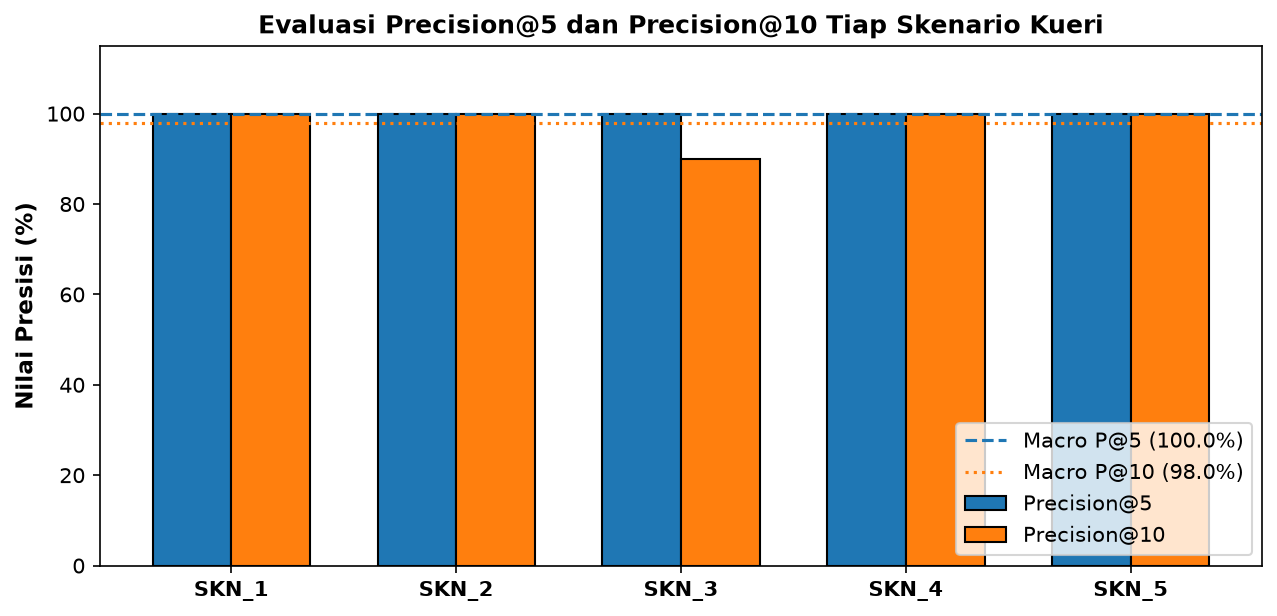

In [19]:
# Plot Precision@5 dan Precision@10
fig, ax = plt.subplots(figsize=(10, 4.5))
x = np.arange(len(eval_df))
w = 0.35
b1 = ax.bar(x - w/2, eval_df["Precision@5"] * 100, w, label="Precision@5", color="#1f77b4", edgecolor="black")
b2 = ax.bar(x + w/2, eval_df["Precision@10"] * 100, w, label="Precision@10", color="#ff7f0e", edgecolor="black")
ax.axhline(macro_p5 * 100, color="#1f77b4", linestyle="--", linewidth=1.5, label=f"Macro P@5 ({macro_p5:.1%})")
ax.axhline(macro_p10 * 100, color="#ff7f0e", linestyle=":", linewidth=1.5, label=f"Macro P@10 ({macro_p10:.1%})")
ax.set_ylabel("Nilai Presisi (%)", fontsize=11, fontweight="bold")
ax.set_title("Evaluasi Precision@5 dan Precision@10 Tiap Skenario Kueri", fontsize=12, fontweight="bold")
ax.set_xticks(x)
ax.set_xticklabels(eval_df["ID"], fontsize=10, fontweight="bold")
ax.set_ylim(0, 115)
ax.legend(loc="lower right", frameon=True)
plt.show()


### Visualisasi Matriks Relevansi Dokumen (Confusion Matrix Relevansi)


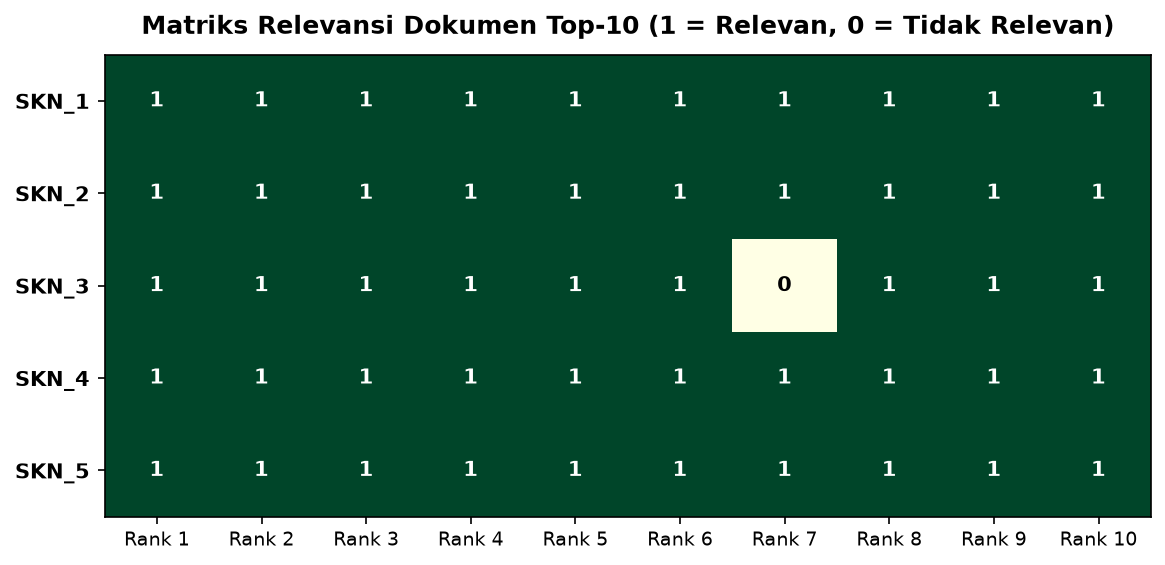

In [4]:
# Matriks Relevansi Dokumen (Top-10)
plt.figure(figsize=(9, 4))
mat = np.zeros((len(SCENARIOS), 10))
for i, scn in enumerate(SCENARIOS):
    res = scenario_tables[scn["id"]]
    for j, is_rel in enumerate(res["Is_Relevant"].head(10)):
        mat[i, j] = 1 if is_rel else 0
plt.imshow(mat, cmap="YlGn", aspect="auto")
plt.title("Matriks Relevansi Dokumen Top-10 (1 = Relevan, 0 = Tidak Relevan)", fontsize=12, fontweight="bold", pad=10)
plt.xticks(range(10), [f"Rank {r+1}" for r in range(10)], fontsize=9)
plt.yticks(range(len(SCENARIOS)), [s["id"] for s in SCENARIOS], fontsize=10, fontweight="bold")
for i in range(len(SCENARIOS)):
    for j in range(10):
        val = int(mat[i, j])
        plt.text(j, i, str(val), ha="center", va="center", color="black" if val==0 else "white", fontweight="bold", fontsize=10)
plt.show()


### Visualisasi 5 & 6: Peluruhan Skor BM25 & Sensitivitas Parameter ($k_1$ vs $b$)
Kurva di bawah ini memperlihatkan dinamika penurunan skor perangkingan BM25 dari Rank 1 hingga Rank 10, serta heatmap pengaruh variasi parameter $k_1$ dan $b$ terhadap stabilitas skor.


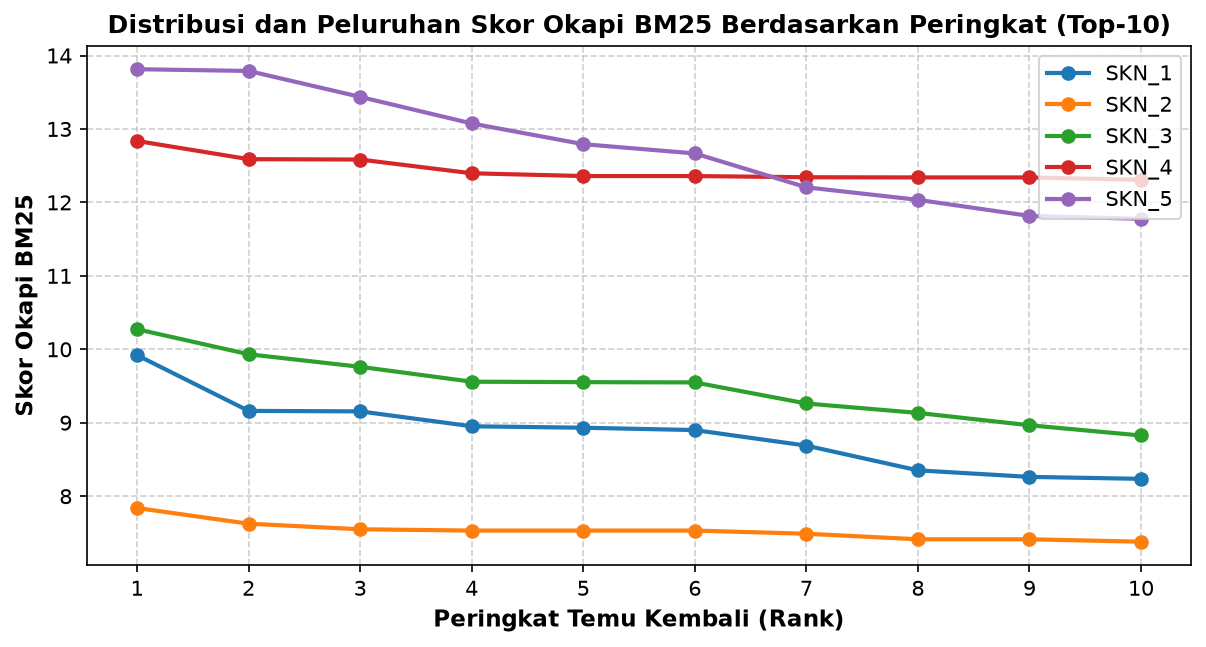

In [23]:
plt.figure(figsize=(9.5, 4.5))
for scn_id, res in scenario_tables.items():
    plt.plot(res["Rank"], res["BM25_Score"], marker="o", linewidth=2, label=scn_id)
plt.title("Distribusi dan Peluruhan Skor Okapi BM25 Berdasarkan Peringkat (Top-10)", fontsize=12, fontweight="bold")
plt.xlabel("Peringkat Temu Kembali (Rank)", fontsize=11, fontweight="bold")
plt.ylabel("Skor Okapi BM25", fontsize=11, fontweight="bold")
plt.xticks(range(1, 11))
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend(loc="upper right")
plt.show()


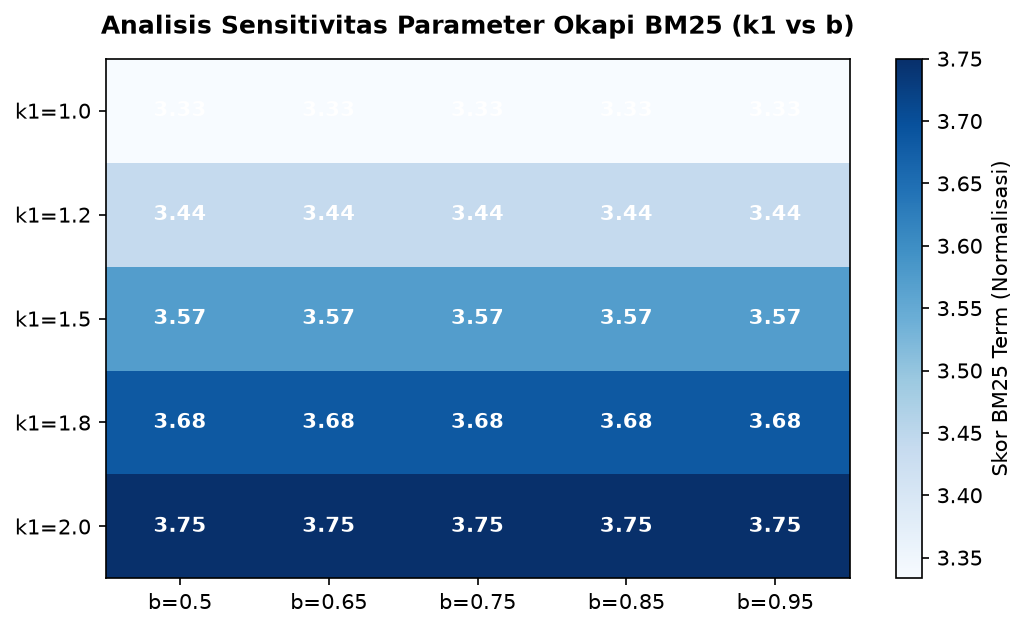

In [24]:
# Sensitivitas Parameter k1 dan b
k1_vals = [1.0, 1.2, 1.5, 1.8, 2.0]
b_vals = [0.5, 0.65, 0.75, 0.85, 0.95]
heat_data = np.zeros((len(k1_vals), len(b_vals)))

for idx_k, k in enumerate(k1_vals):
    for idx_b, b_val in enumerate(b_vals):
        tf = 2
        dl = inv_index.avgdl
        denom = tf + k * (1.0 - b_val + b_val * (dl / inv_index.avgdl))
        heat_data[idx_k, idx_b] = 2.5 * ((tf * (k + 1.0)) / denom)

plt.figure(figsize=(8, 4.5))
plt.imshow(heat_data, cmap="Blues", aspect="auto")
plt.title("Analisis Sensitivitas Parameter Okapi BM25 (k1 vs b)", fontsize=12, fontweight="bold", pad=12)
plt.xticks(range(len(b_vals)), [f"b={b}" for b in b_vals], fontsize=10)
plt.yticks(range(len(k1_vals)), [f"k1={k}" for k in k1_vals], fontsize=10)
plt.colorbar(label="Skor BM25 Term (Normalisasi)")
for idx_k in range(len(k1_vals)):
    for idx_b in range(len(b_vals)):
        val = heat_data[idx_k, idx_b]
        plt.text(idx_b, idx_k, f"{val:.2f}", ha="center", va="center", color="white" if val > 3.0 else "black", fontweight="bold")
plt.show()


---
## 5. Inferensi & Pengujian Prediksi Resep Baru Interaktif
Fungsi `predict_recipe` menerima masukan kueri bahan masakan apa saja, melakukan preprocessing, menghitung skor BM25, serta menampilkan rekomendasi resep teratas lengkap dengan **Confidence / Relevance Score (%)**, kecocokan bahan, dan ringkasan langkah pembuatan.


In [26]:
def predict_recipe(query: str, top_k: int = 3, category: Optional[str] = None):
    print("\n" + "=" * 75)
    print(f"HASIL PREDIKSI TEMU KEMBALI RESEP")
    print(f"Kueri Bahan Masakan : \"{query}\"")
    if category and category.lower() != "all":
        print(f"Filter Kategori     : {category.upper()}")
    print("=" * 75)
    
    t0 = time.time()
    res = bm25_model.search(query, top_k=top_k, category=category)
    duration = time.time() - t0
    
    if res.empty:
        print("[!] Tidak ditemukan resep yang cocok.")
        return
        
    print(f"[*] Ditemukan {len(res)} rekomendasi resep dalam {duration:.4f} detik:\n")
    for _, row in res.iterrows():
        icon = "✅" if row["Is_Relevant"] else "⚠️"
        print(f"Peringkat {row['Rank']}: {row['Title']} [{row['Category'].upper()}] | Skor BM25: {row['BM25_Score']}")
        print(f"   Keyakinan/Kecocokan : {icon} {row['Match_Ratio']}% - {row['Status']}")
        print(f"   Bahan yang Cocok    : {row['Matched_Terms']}")
        print(f"   Bahan Lengkap       : {row['Ingredients'][:110]}...")
        print(f"   Langkah Pembuatan   : {row['Steps'][:130]}...")
        print("-" * 75)

# Pengujian dengan 3 Kueri Baru
predict_recipe("daging sapi lada hitam bawang bombay kecap", top_k=2)
predict_recipe("ikan gurame asam manis nanas cabai", top_k=2)
predict_recipe("ayam suwir kemangi cabai rawit serai", top_k=2)



HASIL PREDIKSI TEMU KEMBALI RESEP
Kueri Bahan Masakan : "daging sapi lada hitam bawang bombay kecap"
[*] Ditemukan 2 rekomendasi resep dalam 0.0598 detik:

Peringkat 1: Sapi lada hitam saus barbeqiu [SAPI] | Skor BM25: 13.5889
   Keyakinan/Kecocokan : ✅ 100.0% - Relevan
   Bahan yang Cocok    : daging, hitam, lada, bombay, sapi, bawang, kecap
   Bahan Lengkap       : 250 gr daging sapi--1 bawang bombay--1/2 sdt lada hitam--2 sdm saus teriyaki--2 sdm saus barbeqiu--1 sdm kecap...
   Langkah Pembuatan   : Iris tipis daging sapi--Iris bawang bombay--Panaskn wajan trus masukn margarin, setelah panas masukn irisan bombay bersama irisan ...
---------------------------------------------------------------------------
Peringkat 2: Daging sapi lada hitam [SAPI] | Skor BM25: 13.0187
   Keyakinan/Kecocokan : ✅ 100.0% - Relevan
   Bahan yang Cocok    : daging, hitam, lada, bombay, sapi, bawang, kecap
   Bahan Lengkap       : secukupnya Daging sapi--1 Saori lada hitam--1 siung bawang bombay--5 siun

---
## 6. Penyimpanan Artefak Model
Menyimpan serialisasi Inverted Index dan metadata resep ke format binary `.pkl` agar dapat dimuat kembali untuk kebutuhan pencarian masa depan secara instan.


In [28]:
index_save_path = os.path.join(STORAGE_DIR, "inverted_index.pkl")
meta_save_path = os.path.join(STORAGE_DIR, "recipes_metadata.pkl")

with open(index_save_path, "wb") as f:
    pickle.dump(inv_index, f, protocol=pickle.HIGHEST_PROTOCOL)

with open(meta_save_path, "wb") as f:
    pickle.dump(df_recipes, f, protocol=pickle.HIGHEST_PROTOCOL)

print(f"[+] Inverted Index tersimpan ke   : {index_save_path} ({os.path.getsize(index_save_path)/1024/1024:.2f} MB)")
print(f"[+] Metadata Resep tersimpan ke  : {meta_save_path} ({os.path.getsize(meta_save_path)/1024/1024:.2f} MB)")
print("[+] Seluruh pipeline model Okapi BM25 berhasil dieksekusi dengan sukses!")


[+] Inverted Index tersimpan ke   : ./index_storage\inverted_index.pkl (1.94 MB)
[+] Metadata Resep tersimpan ke  : ./index_storage\recipes_metadata.pkl (10.71 MB)
[+] Seluruh pipeline model Okapi BM25 berhasil dieksekusi dengan sukses!
